In [2]:
import pandas as pd
import numpy as np
from math import e
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", None)


column_types = {
    "id": "Int64",
    "osm_id": "str",
    "addr_street": "str",
    "addr_number": "str",
    "ground_floor_group": "str",
    "ground_floor_function": "str",
    "upper_floor_group": "str",
    "upper_floor_function": "str",
    "number_of_storeys": "Int64",
    "is_mixed_use": "boolean",
    "build_year_est": "Int64",
    "arch_style": "str",
    "condition": "Int64",
    "max_height": "float64",
    "is_heritage": "str",
    "source": "str",
    "confidence": "Int64",
    "date_of_checking": "str",
    "number_of_functions": "Int64",
}

In [3]:
data_gdynia_parsed = pd.read_csv(
    "../data/processed/fixed/srodmiescie.csv",
    sep=";",
    index_col=0,
    dtype=column_types,
    parse_dates=["date_of_checking"],
)

data_gdynia_unparsed = pd.read_csv(
    "../data/processed/fixed/srodmiescie.csv", sep=";", index_col=0, dtype=column_types
)

1.

In [4]:
print(f"unparsed type: {data_gdynia_unparsed['date_of_checking'].dtype}")
print(f"parsed type: {data_gdynia_parsed['date_of_checking'].dtype}")

print(f"min_unparsed: {data_gdynia_unparsed['date_of_checking'].min()}")
print(f"max_unparsed: {data_gdynia_unparsed['date_of_checking'].max()}")
print(f"min_parsed: {data_gdynia_parsed['date_of_checking'].min()}")
print(f"max_parsed: {data_gdynia_parsed['date_of_checking'].max()}")

unparsed type: str
parsed type: datetime64[us]
min_unparsed: 2026-09-23
max_unparsed: 2026-09-30
min_parsed: 2026-09-23 00:00:00
max_parsed: 2026-09-30 00:00:00


In [5]:
data_gdynia_parsed["date_of_checking"].dt.day

id
1       27
2       27
3       27
4       27
5       27
        ..
1236    30
1237    30
1238    30
1239    30
1241    30
Name: date_of_checking, Length: 982, dtype: int32

In [6]:
pd.testing.assert_series_equal(
    data_gdynia_parsed["date_of_checking"],
    pd.to_datetime(data_gdynia_unparsed["date_of_checking"]),
)
assert data_gdynia_parsed["date_of_checking"].nunique() == 7
assert data_gdynia_parsed["date_of_checking"].isna().sum() == 0

2.

In [7]:
data_gdynia_parsed["date_of_checking_daynumber"] = data_gdynia_parsed[
    "date_of_checking"
].dt.day_of_week
data_gdynia_parsed["date_of_checking_dayofweek"] = data_gdynia_parsed[
    "date_of_checking"
].dt.day_name()
data_gdynia_parsed

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,date_of_checking,number_of_functions,date_of_checking_daynumber,date_of_checking_dayofweek
id,,,,,,,,,,,,,,,,,,,,
1,127184291,Świętego Piotra,8,NaN,hotel,NaN,hotel,7,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1,6,Sunday
2,890729731,Świętego Piotra,6D,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,5,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1,6,Sunday
3,890292040,Węglowa,22,NaN,centrum handlowe,NaN,mieszkaniowa wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1,6,Sunday
4,890729732,Świętego Piotra,6,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,17,<NA>,2020,współczesność,3,NaN,NaN,google.com/maps,3,2026-09-27,1,6,Sunday
5,136885205,Tadeusza Wendy,15,NaN,centrum medyczne,NaN,centrum medyczne,6,<NA>,2000,współczesność,3,NaN,NaN,google.com/maps,2,2026-09-27,1,6,Sunday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1236,205167460,NaN,NaN,NaN,techniczna,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,2026-09-30,1,2,Wednesday
1237,126180359,Władysława IV,61,NaN,"laboratorium medyczne,piekarnia,kiosk",NaN,mieszkaniowa wielorodzinna,7,<NA>,1940,modernizm,3,NaN,NaN,google.com/maps,2,2026-09-30,3,2,Wednesday
1238,126173503,Świętojańska,122,NaN,"apteka,handel zdrowie",NaN,biurowa,6,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,2026-09-30,2,2,Wednesday


In [8]:
data_gdynia_parsed.groupby(
    ["date_of_checking_dayofweek", "date_of_checking_daynumber"]
).size()

date_of_checking_dayofweek  date_of_checking_daynumber
Friday                      4                              67
Saturday                    5                             100
Sunday                      6                             461
Thursday                    3                             108
Tuesday                     1                              22
Wednesday                   2                             224
dtype: int64

In [9]:
(data_gdynia_parsed["date_of_checking_daynumber"] >= 5).mean()

np.float64(0.5712830957230143)

In [10]:
pd.Timestamp("2026-09-23").day_name()

'Wednesday'

In [11]:
assert data_gdynia_parsed.groupby("date_of_checking_dayofweek").size().sum() == 982
assert np.isclose(
    len(data_gdynia_parsed.loc[data_gdynia_parsed["date_of_checking_daynumber"] >= 5])
    / data_gdynia_parsed.groupby("date_of_checking_dayofweek").size().sum(),
    0.571,
    atol=0.01,
)

3.

In [12]:
data_gdynia_parsed["week_of_checking"] = data_gdynia_parsed[
    "date_of_checking"
].dt.isocalendar()["week"]
buil_per_week = data_gdynia_parsed.groupby("week_of_checking").size()

In [13]:
assert buil_per_week.sum() == 982
assert buil_per_week.loc[39] == 788
assert buil_per_week.loc[40] == 194

4.

In [14]:
REF = pd.Timestamp("2026-10-17")

In [15]:
data_gdynia_parsed["days_since_checking"] = (
    REF - data_gdynia_parsed["date_of_checking"]
).dt.days
data_gdynia_parsed["days_since_checking"].describe()

count    982.000000
mean      20.209776
std        1.959005
min       17.000000
25%       20.000000
50%       20.000000
75%       21.000000
max       24.000000
Name: days_since_checking, dtype: float64

In [16]:
assert data_gdynia_parsed["days_since_checking"].min() == 17
assert data_gdynia_parsed["days_since_checking"].max() == 24
assert np.isclose(data_gdynia_parsed["days_since_checking"].mean(), 20.21, atol=0.01)
assert (data_gdynia_parsed["days_since_checking"] > 20).sum() == 327

5.

In [17]:
data_groupby = data_gdynia_parsed.groupby("date_of_checking").size()

data_resample = data_gdynia_parsed.set_index("date_of_checking").resample("D").size()
data_resample

date_of_checking
2026-09-23     52
2026-09-24    108
2026-09-25     67
2026-09-26    100
2026-09-27    461
2026-09-28      0
2026-09-29     22
2026-09-30    172
Freq: D, dtype: int64

In [18]:
assert data_resample.loc["2026-09-28"] == 0
assert data_resample.sum() == 982
pd.testing.assert_series_equal(data_groupby, data_resample.loc[data_resample != 0])

6.

In [19]:
date_resample_6 = (
    data_gdynia_parsed.assign(conf_3=lambda d: d["confidence"] == 3)
    .resample("D", on="date_of_checking")
    .agg(
        num_build=("osm_id", "size"),
        num_streets=("addr_street", "nunique"),
        share_build_conf_3=("conf_3", "mean"),
    )
)

In [20]:
date_resample_6.loc["2026-09-27", "num_build"] == 461
date_resample_6.loc["2026-09-27", "num_streets"] == 34


np.True_

In [21]:
assert date_resample_6.sort_values("share_build_conf_3", ascending=False).index[
    0
] == pd.Timestamp("2026-09-25")

7.

In [22]:
data_date_style = (
    data_gdynia_parsed.groupby(
        [pd.Grouper(key="date_of_checking", freq="D"), "arch_style"]
    )
    .size()
    .unstack(fill_value=0)
)
data_date_style

arch_style,klasycyzm,modernizm,postmodernizm,tradycjonalizm,współczesność
date_of_checking,,,,,
2026-09-23,5,28,0,0,19
2026-09-24,15,30,3,0,60
2026-09-25,5,21,0,4,37
2026-09-26,12,30,0,0,58
2026-09-27,7,222,1,3,228
2026-09-29,1,18,0,0,3
2026-09-30,4,117,0,0,51


In [23]:
data_date_style.sum(axis=1)

date_of_checking
2026-09-23     52
2026-09-24    108
2026-09-25     67
2026-09-26    100
2026-09-27    461
2026-09-29     22
2026-09-30    172
dtype: int64

In [24]:
assert (data_groupby == (data_date_style.sum(axis=1))).all()
assert data_date_style.loc["2026-09-27", "modernizm"] == 222
assert data_date_style.loc["2026-09-27", "współczesność"] == 228

8.

In [25]:
data_weekend = (
    data_gdynia_parsed.set_index("date_of_checking")
    .sort_index()
    .loc["2026-09-26":"2026-09-27"]
)

In [26]:
data_weekend

,osm_id,addr_street,addr_number,ground_floor_group,ground_floor_function,upper_floor_group,upper_floor_function,number_of_storeys,is_mixed_use,build_year_est,arch_style,condition,max_height,is_heritage,source,confidence,number_of_functions,date_of_checking_daynumber,date_of_checking_dayofweek,week_of_checking,days_since_checking
date_of_checking,,,,,,,,,,,,,,,,,,,,,
2026-09-26,260800937,NaN,NaN,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,4,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,1,5,Saturday,39,21
2026-09-26,241327986,NaN,NaN,NaN,garaż,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,1,5,Saturday,39,21
2026-09-26,126391720,Świętojańska,16,NaN,apteka,NaN,mieszkaniowa wielorodzinna,5,<NA>,1930,modernizm,2,NaN,NaN,google.com/maps,2,1,5,Saturday,39,21
2026-09-26,126596719,10 Lutego,6B,NaN,kantor,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,2,1,5,Saturday,39,21
2026-09-26,260800840,NaN,NaN,NaN,garaż,NaN,NaN,1,<NA>,1980,współczesność,2,NaN,NaN,google.com/maps,3,1,5,Saturday,39,21
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-27,227114783,Wójta Radtkego,NaN,NaN,mieszkaniowa wielorodzinna,NaN,mieszkaniowa wielorodzinna,2,<NA>,2000,współczesność,2,NaN,NaN,google.com/maps,2,1,6,Sunday,39,20
2026-09-27,126897563,Wójta Radtkego,42,NaN,restauracja,NaN,mieszkaniowa wielorodzinna,5,<NA>,1940,modernizm,2,NaN,NaN,google.com/maps,2,1,6,Sunday,39,20
2026-09-27,126897570,Wójta Radtkego,33,NaN,"handlowa sprzęt,handlowa zdrowie",NaN,mieszkaniowa wielorodzinna,7,<NA>,1950,modernizm,3,NaN,NaN,google.com/maps,2,2,6,Sunday,39,20


this slicing differ from [a:b] method becouse right part in dates or other labels is inclusive where normally its not inclusive

In [27]:
assert len(
    data_gdynia_parsed.loc[
        data_gdynia_parsed["date_of_checking"].between("2026-09-26", "2026-09-27")
    ]
) == len(data_weekend)

9.

In [28]:
data_gdynia_dates = data_gdynia_parsed.groupby("addr_street").agg(
    first_date=("date_of_checking", "min"),
    last_date=("date_of_checking", "max"),
    num_dates=("date_of_checking", "nunique"),
).assign(
    range_dates=lambda d: (d["last_date"] - d["first_date"]).dt.days,
    days_since_last=lambda d: (REF - d["last_date"]).dt.days,
)
data_gdynia_dates.loc[data_gdynia_dates['days_since_last']>20]

,first_date,last_date,num_dates,range_dates,days_since_last
addr_street,,,,,
Hilarego Jastaka,2026-09-25,2026-09-25,1,0,22
Mściwoja,2026-09-23,2026-09-24,2,1,23
Szkolna,2026-09-24,2026-09-24,1,0,23
Zgoda,2026-09-23,2026-09-24,2,1,23
Zygmunta Augusta,2026-09-26,2026-09-26,1,0,21


In [29]:
assert (data_gdynia_dates.loc['Świętojańska'] == [pd.Timestamp("2026-09-24"),pd.Timestamp("2026-09-30"),5,6,17]).all()
assert len(data_gdynia_dates) == 44
assert len(data_gdynia_dates.loc[data_gdynia_dates['days_since_last']>20]) == 5

10.

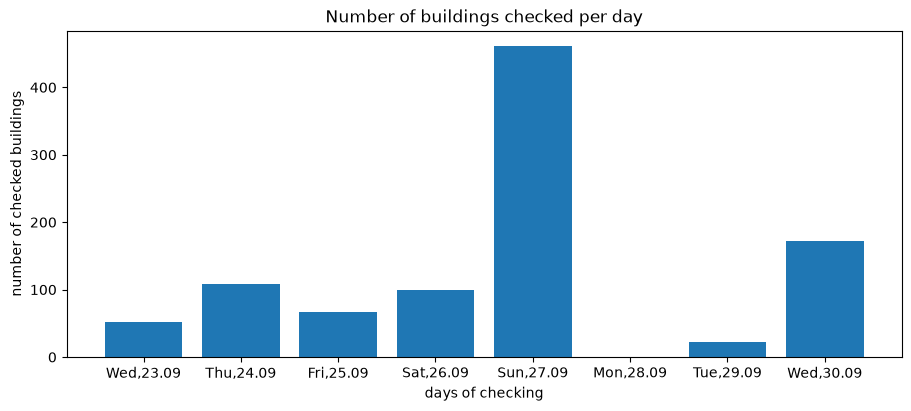

In [30]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")

ax.bar(data_resample.index.strftime('%a,%d.%m'), data_resample.values)
ax.set_xlabel('days of checking')
ax.set_ylabel('number of checked buildings')
ax.set_title('Number of buildings checked per day')
plt.show()